## Libraries and Preparation

In [2]:
pip install iterative-stratification

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]="0"

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.transforms.functional as F_transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cv2
import graphviz
import pytorch_lightning as pl
import torchmetrics
import wandb
from tqdm import tqdm
from PIL import Image
from torchvision import models

!pip install torchview
from torchview import draw_graph
from scipy.ndimage import gaussian_laplace
from pytorch_lightning.loggers import WandbLogger
from pytorch_lightning.callbacks import ModelCheckpoint, LearningRateMonitor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from torchvision.transforms import ToTensor

from torch.utils.data import Dataset
from torchvision import datasets
import timm
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
import imagehash

%matplotlib inline

In [4]:
DEVICE = "cuda"

In [5]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('cats-and-dogs')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/cats-and-dogs


In [6]:
train_df = pd.read_csv('/kaggle/input/competitions/cats-and-dogs/train.csv')

## Exploratory Data Analysis

In [7]:
label_cols = ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
train_df['num_labels'] = train_df[label_cols].sum(axis=1)
#train_df[(train_df['Moris'] == 1) & (train_df['Motya'] == 1)]
train_df.head(5)

,image_id,Cat,Dog,Moris,Motya,Biatrix,num_labels
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0,1
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0,1
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0,1
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0,1


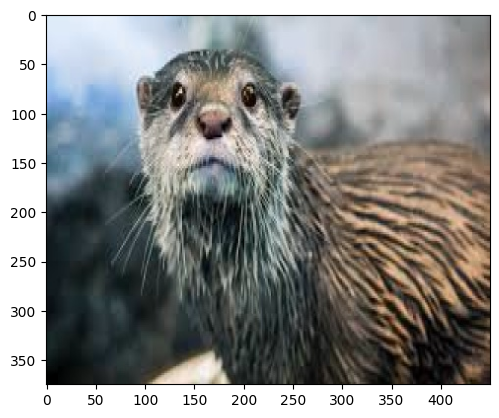

In [8]:
image = cv2.imread('/kaggle/input/competitions/cats-and-dogs/train/7e17a6e589f9c891857b32bbb3652d19b7d5a215.jpg')

plt.imshow(image)

**QUESTION: "Do we have duplicates by image IDs?"**

In [9]:
print(f"Overall count: {train_df['image_id'].count()}")
print(f"Distinct count: {train_df['image_id'].nunique()}")

Overall count: 12260
Distinct count: 12260


The training dataset contains 12,260 total samples with 12,260 distinct image_id entries, confirming there are no duplicate records or primary key collisions.

**QUESTION: "How many visual duplicates do we have?"**

In [10]:
import imagehash

hash_dict = {}
duplicate_groups = []

for img_id in tqdm(train_df['image_id'].values):
    img_path = f'/kaggle/input/competitions/cats-and-dogs/train/{img_id}.jpg'
    
    with Image.open(img_path) as img:
        img_hash = str(imagehash.phash(img))
        
    if img_hash in hash_dict:
        hash_dict[img_hash].append(img_id)
    else:
        hash_dict[img_hash] = [img_id]

for h, id_list in hash_dict.items():
    if len(id_list) > 1:
        duplicate_groups.append(id_list)

print(f"\Found {len(duplicate_groups)} duplicates.")

if duplicate_groups:
    for i, group in enumerate(duplicate_groups[:5]):
        print(f"Group {i+1}: {group}")

<>:21: SyntaxWarning: invalid escape sequence '\F'
<>:21: SyntaxWarning: invalid escape sequence '\F'
/tmp/ipykernel_49/1078756767.py:21: SyntaxWarning: invalid escape sequence '\F'
  print(f"\Found {len(duplicate_groups)} duplicates.")
100%|██████████| 12260/12260 [04:06<00:00, 49.72it/s]

\Found 124 duplicates.
Group 1: ['065e443c7d689e01c78c4963e49a2cff6acddcc8', '6171a006f7ea6c742624cb80e4d975738515febc']
Group 2: ['9997e4d9aca1d96856c71ad941af7edfbf374da9', 'c101ec2eec36c5147886da8e59e32a28666e55f0']
Group 3: ['d0e3d34bdbea97bffe485af98e61c0e633b7def2', '61c156e26b1f3d69e6b234b5fff82ddab3f8348f']
Group 4: ['b157418f6c969f9dbb3151e39c8945eb7bcde7e0', 'fdf0f3befd2bfef71f1d49620c75ff5dbc8f7565']
Group 5: ['73446eeb71bee385435f4931754b5c42d20ecc3e', '62aaa1f2555524eb12bdaa088a341782d8c3fe15']


Here we have a clear indication of possible data leakage. We have 124 visual duplicates and if we will not erase them during preprocessing, we can get the same image in train and validation sets. The model will "memorize" the images, which will artificially inflate our local metric (CV) but lead to failure on the actual Kaggle test set.

**QUESTION: "How many labels per row?"**

In [11]:
labels_per_image_count = train_df['num_labels'].value_counts().sort_index()
labels_per_image_prop = train_df['num_labels'].value_counts(normalize=True).sort_index() * 100

dist_df = pd.DataFrame({
    'Count': labels_per_image_count,
    'Percentage (%)': labels_per_image_prop.round(2)
})

dist_df

,Count,Percentage (%)
num_labels,,
0,2162,17.63
1,9973,81.35
2,111,0.91
3,10,0.08
4,4,0.03


The label distribution reveals that despite the multi-label setup, the dataset behaves predominantly as a single-label problem, with 81.35% of images containing exactly one label. Additionally, a significant 17.63% of the data contains zero target labels, acting as a background class that requires the model to be well-calibrated against false positives. True multi-label instances containing two or more labels are extremely sparse at roughly 1% of the dataset, which strictly necessitates multi-label stratified cross-validation to ensure these rare combinations are properly represented across all training and validation splits.

**QUESTION: "How many labels do we have per category?**

In [12]:
temp_df = train_df[label_cols].copy()
temp_df['Other'] = (temp_df.sum(axis=1) == 0).astype(int)

all_cols = label_cols + ['Other']

categories_summary = pd.DataFrame({
    'Count': temp_df[all_cols].sum(),
    'Percentage (%)': (temp_df[all_cols].mean() * 100).round(2)
})

categories_summary.loc['Total'] = categories_summary.sum()
categories_summary

,Count,Percentage (%)
Cat,5077.0,41.41
Dog,5025.0,40.99
Moris,56.0,0.46
Motya,42.0,0.34
Biatrix,41.0,0.33
Other,2162.0,17.63
Total,12403.0,101.16


This distribution represents inbalanced data. Standard random splitting will likely result in validation folds that miss some of these rare classes entirely. Therefore, it is important to apply stratified CV in this case. Moreover this severe class skew necessitates specialized multi-label handling, such as loss weighting.

**QUESTION: "What shapes do we have across the images?"**

In [13]:
pil_shapes = []
for img_name in tqdm(train_df['image_id'].values):
    img_path = os.path.join("/kaggle/input/competitions/cats-and-dogs/train", f"{img_name}.jpg")
    with Image.open(img_path) as img:
        pil_shapes.append(img.size) 

print(pd.Series(pil_shapes).value_counts())

100%|██████████| 12260/12260 [00:11<00:00, 1027.67it/s]

(450, 375)    12260
Name: count, dtype: int64


Analysis of image dimensions across the entire dataset revealed a uniform spatial resolution of $375 \times 450$ pixels (Height $\times$ Width) for all 12,260 training samples. Consequently, no custom padding or dynamic resizing per batch is required. However, we should convert it to square size when training.

**QUESTION: "How does every label look?"**

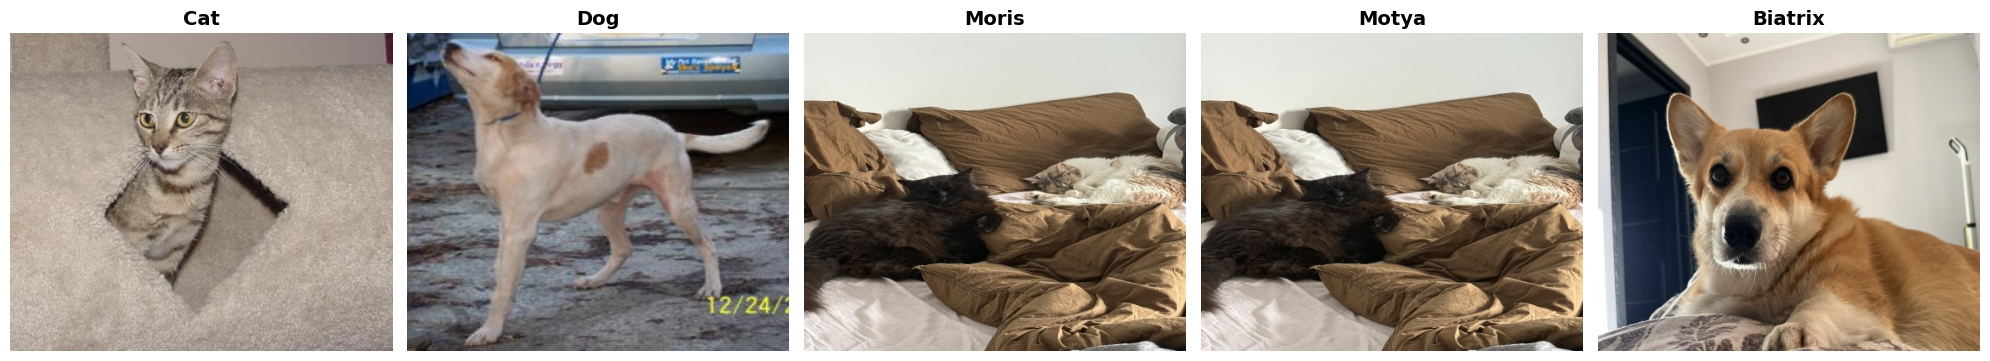

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, label in enumerate(label_cols):
    img_id = train_df[train_df[label] == 1]['image_id'].iloc[0]
    img_path = f'/kaggle/input/competitions/cats-and-dogs/train/{img_id}.jpg'
    
    image = cv2.imread(img_path)
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(image)
    axes[i].set_title(label, fontsize=14, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Two cats on both labels. Let's look where is Moris and where is Motya

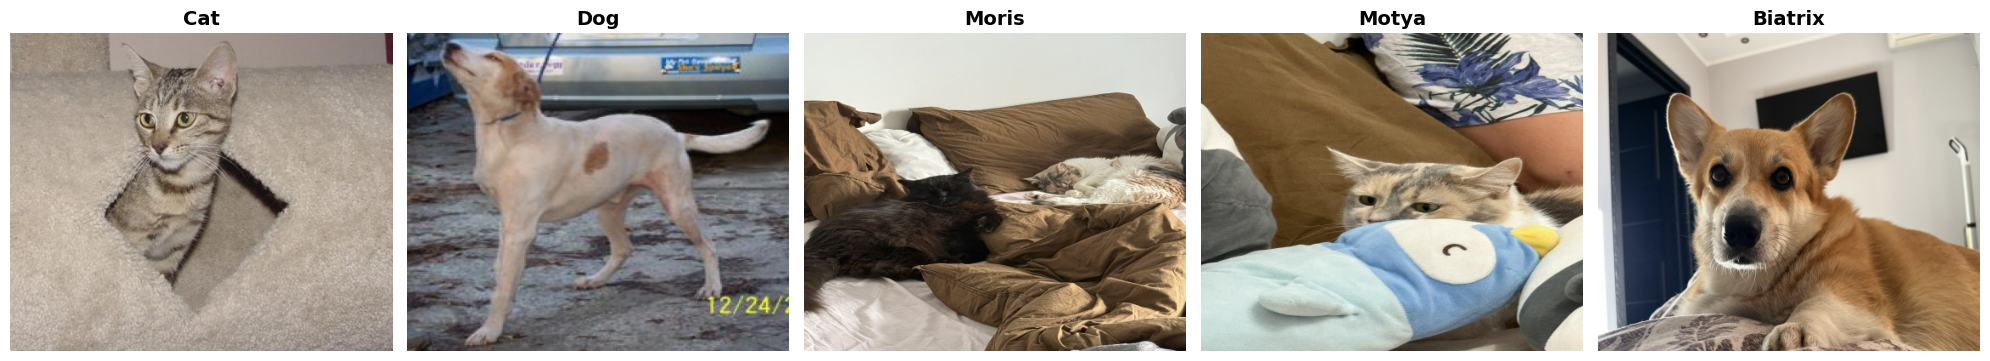

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
used_image_ids = set()

for i, label in enumerate(label_cols):
    condition = ((train_df[label] == 1) & (~train_df['image_id'].isin(used_image_ids)))
    
    filtered_df = train_df[condition]
    
    if len(filtered_df) > 0:
        img_id = filtered_df['image_id'].iloc[0]
    else:
        fallback_df = train_df[(train_df[label] == 1) & (~train_df['image_id'].isin(used_image_ids))]
        if len(fallback_df) > 0:
            img_id = fallback_df['image_id'].iloc[0]
        else:
            img_id = train_df[train_df[label] == 1]['image_id'].iloc[0]
            
    used_image_ids.add(img_id)
    
    img_path = f'/kaggle/input/competitions/cats-and-dogs/train/{img_id}.jpg'
    
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(image)
    axes[i].set_title(label, fontsize=14, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

**QUESTION: "Do we have same labels on duplicate images?"**

In [16]:
conflict_groups = []

for group in duplicate_groups:
    group_df = train_df[train_df['image_id'].isin(group)]
    
    unique_labels = group_df[label_cols].drop_duplicates()
    
    if len(unique_labels) > 1:
        conflict_groups.append(group_df)

print(f"Found conflict groups: {len(conflict_groups)}")

if len(conflict_groups) > 0:
    for i, df_conf in enumerate(conflict_groups[:3]):
        print(f"\n--- Conflict group {i+1} ---")
        print(df_conf[['image_id'] + label_cols])
else:
    print("All visual duplicates have identical labels")

Found conflict groups: 0
All visual duplicates have identical labels


Therefore, we can randomly delete on of two images in a duplicate group

## Metric Justification

**Proposed Metric: F1 Score**

The core strengh of proposed macro F1 metric is that it calculates the F1 score for each of the 5 classes independently and then takes the unweighted average. This forces the model to treat the rare classes as equally important as the dominant classes. It actively punishes models that lazily predict only cats and dogs.

However, a single misclassification or a noisy label in a tiny class can cause its individual F1-score to plummet. Since we have less than 1% of rare class, this moise is very possible to happen.

**Complementary Metrics**

It is worth computing Micro F1 along with Macro F1 to measure overall global accuracy without the heavy penalty of the rare classes.

Additionally, tracking Binary Cross-Entropy Loss is crucial because it evaluates continuous probabilities rather than hard thresholds, showing if the model is actually learning even if the F1 score hasn't improved yet.

**Alternative metrics and Justification**

As an alternative metric PR-AUC acts as an ideal alternative metric for this dataset because it effectively handles extreme class imbalance by completely ignoring True Negatives, which are overwhelmingly abundant in this multi-label task. Unlike ROC-AUC, which can show a misleadingly high score due to the massive number of easy negative predictions, PR-AUC focuses exclusively on the model's accuracy in predicting true positives in all predicted positives and its ability to find all actual positives across all probability thresholds. This ensures an objective evaluation of rare classes without being artificially affected by the dominant background class, while also avoiding the chaotic fluctuations caused by the hard thresholding of the Macro F1 score.

## Validation



**Validation Strategy** 

Multilabel Stratified 5-Fold Cross-Validation

**Why this?** 

The dataset demonstrates an extreme imbalance with rare classes appearing in less than 1% of instances and a multi-label structure. Simple random splitting or standard stratification could result in a rare class being entirely absent from a validation fold. Iterative multi-label stratification ensures that the proportions of both individual labels and their rare intersections are preserved across all folds.

**Correlation with leaderboard results**

We expect that multi-label stratification successfully balances the complexity of the folds, and strong augmentations prevent overfitting to the dominant classes Cat and Dog.

However, since the macro F1 score averages results across classes without accounting for their size, we can end up with a significantly lower score due to just a few errors on rare classes.

## Adversarial Validation (optional)

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

backbone = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
backbone.classifier = torch.nn.Identity()
backbone.to(device)
backbone.eval()

transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_subset = train_df.sample(n=500, random_state=42).copy()
train_subset['is_test'] = 0

test_df = pd.read_csv("/kaggle/input/competitions/cats-and-dogs/test.csv")
test_subset = test_df.sample(n=500, random_state=42).copy()
test_subset['is_test'] = 1

adv_df = pd.concat([train_subset, test_subset]).reset_index(drop=True)

features = []
labels = []

for idx, row in tqdm(adv_df.iterrows(), total=len(adv_df)):
    img_id = row['image_id']
    is_test = row['is_test']
    
    if is_test == 0:
        img_path = f'/kaggle/input/competitions/cats-and-dogs/train/{img_id}.jpg'
    else:
        img_path = f'/kaggle/input/competitions/cats-and-dogs/test/{img_id}.jpg'
        
    try:
        with Image.open(img_path).convert('RGB') as img:
            tensor_img = transform(img).unsqueeze(0).to(device)
            
            with torch.no_grad():
                feat = backbone(tensor_img).cpu().numpy().flatten()
                
            features.append(feat)
            labels.append(is_test)
    except Exception as e:
        continue

features = np.array(features)
labels = np.array(labels)

X_train, X_val, y_train, y_val = train_test_split(
    features, 
    labels, 
    test_size=0.3, 
    random_state=42, 
    stratify=labels
)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train)

preds = clf.predict_proba(X_val)[:, 1]
auc_score = roc_auc_score(y_val, preds)

print(f"\nReal Adversarial Validation ROC-AUC Score: {auc_score:.4f}")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 189MB/s]
100%|██████████| 1000/1000 [00:28<00:00, 35.11it/s]



Real Adversarial Validation ROC-AUC Score: 0.4158


Finally, there is no domain shift in train and test data

## Preprocessing

In [18]:
# 1. Duplicate Removal

ids_to_drop = []
for group in duplicate_groups:
    ids_to_drop.extend(group[1:])

train_df = train_df[~train_df['image_id'].isin(ids_to_drop)].reset_index(drop=True)



# 2. Two-layer label encoder

class HierarchicalLabelEncoder:
    def __init__(self, label_columns):
        self.label_columns = label_columns
        
    def encode(self, row):
        labels = row[self.label_columns].values.astype(np.float32)

        if labels.sum() == 0:
            return labels
        if labels[2] == 1 or labels[3] == 1:  # Moris or Motya
            labels[0] = 1  # Cat
        if labels[4] == 1:                     # Biatrix
            labels[1] = 1  # Dog
            
        return labels

encoder = HierarchicalLabelEncoder(label_cols)



# 3. Square padding + resize

class SquarePad:
    def __call__(self, image):
        w, h = image.size
        max_wh = max(w, h)
        hp = (max_wh - w) // 2
        vp = (max_wh - h) // 2
        padding = (hp, vp, max_wh - w - hp, max_wh - h - vp)
        return F_transforms.pad(image, padding, fill=0, padding_mode='constant')


train_transform = transforms.Compose([
    SquarePad(),
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.2)),
])

val_transform = transforms.Compose([
    SquarePad(),
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## CNN

In [19]:
CLASSES = ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']

Model options: efficientnet_b3, convnext_tiny, resnet50, convnextv2_tiny, regnety_016, resnet50d

In [20]:
MODEL_NAME = "convnextv2_tiny"
EPOCHS = 20
LR = 1e-4
WEIGHT_DECAY = 0.05
BATCH_SIZE = 16
DROP_RATE = 0.2
DROP_PATH = 0.1
FOLD = 0
DATA_PATH = '/kaggle/input/competitions/cats-and-dogs/train'

In [21]:
def create_folds(input_df):
    mskf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=95431)
    input_df["fold"] = -1
    for fold, (_, val_idx) in enumerate(mskf.split(input_df, input_df[CLASSES].values)):
        input_df.loc[val_idx, "fold"] = fold
    return input_df

class CatDogDataset(Dataset):
    def __init__(self, input_df, label_cols, path, transform=None):
        self.input_df = input_df
        self.label_cols = label_cols
        self.path = path
        self.transform = transform
        if transform is None:
            raise ValueError("transform is a necessity")

    def __len__(self):
        return len(self.input_df)

    def __getitem__(self, idx):
        row = self.input_df.iloc[idx]
        img_id = row['image_id']
        img_path = os.path.join(self.path, f"{img_id}.jpg")
        image = Image.open(img_path).convert('RGB')
        img_tensor = self.transform(image)
        labels = row[self.label_cols].values.astype('float32')
        labels_tensor = torch.tensor(labels, dtype=torch.float32)
        return img_tensor, labels_tensor

In [22]:
train_df = create_folds(train_df)
train_df[label_cols] = np.stack(train_df.apply(encoder.encode, axis=1).values)

train_part = train_df[train_df["fold"] != FOLD].reset_index(drop=True)
val_part = train_df[train_df["fold"] == FOLD].reset_index(drop=True)
print(len(train_part), len(val_part))

train_dataset = CatDogDataset(train_part, CLASSES, DATA_PATH, transform=train_transform)
val_dataset = CatDogDataset(val_part, CLASSES, DATA_PATH, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False,
                        num_workers=2, pin_memory=True)

pos = train_part[CLASSES].sum().values.astype(np.float32)
raw_pw = (len(train_part) - pos) / np.clip(pos, 1, None)
pos_weight = torch.tensor(np.sqrt(raw_pw), dtype=torch.float32, device=DEVICE)
print("pos_weight:", pos_weight.cpu().numpy().round(2))

9709 2427
pos_weight: [ 1.18  1.19 14.82 16.87 17.39]


In [23]:
class HierarchicalHead(nn.Module):
    def __init__(self, in_features, drop_rate=0.2):
        super().__init__()
        mid = 512
        self.shared = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(drop_rate),
            nn.Linear(in_features, mid),
            nn.GELU(),
        )
        
        self.coarse = nn.Sequential(nn.Dropout(drop_rate / 2), nn.Linear(mid, 2))
        
        self.fine = nn.Sequential(nn.Dropout(drop_rate / 2), nn.Linear(mid, 3))

    def forward(self, x):
        h = self.shared(x)
        return torch.cat([self.coarse(h), self.fine(h)], dim=1)

In [41]:
def build_model(model_name, drop_path=DROP_PATH, drop_rate=DROP_RATE,
                use_custom_head=True):
    backbone = timm.create_model(
        model_name, pretrained=True, num_classes=0,
        drop_rate=drop_rate, drop_path_rate=drop_path
    )
    in_features = backbone.num_features

    if use_custom_head:
        head = HierarchicalHead(in_features, drop_rate=drop_rate)
    else:
        head = nn.Linear(in_features, len(CLASSES))

    model = nn.Sequential(backbone, head)
    return model

class CatDogLitModel(pl.LightningModule):
    def __init__(self, model_name=MODEL_NAME, lr=LR, weight_decay=WEIGHT_DECAY,
                 epochs=EPOCHS, pos_weight=None, drop_rate=DROP_RATE, drop_path=DROP_PATH):
        super().__init__()
        self.save_hyperparameters(ignore=["pos_weight"])
        self.model = build_model(model_name, drop_path=drop_path, drop_rate=drop_rate)
        self.criterion = nn.BCEWithLogitsLoss(
            pos_weight=pos_weight if pos_weight is not None else None
        )
        self.val_probs = []
        self.val_targets = []

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        probs = torch.sigmoid(logits)
        self.val_probs.append(probs.cpu())
        self.val_targets.append(y.cpu())
        self.log("val_bce", loss, on_step=False, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        probs = enforce_hierarchy(torch.cat(self.val_probs).numpy())
        targets = torch.cat(self.val_targets).numpy().astype(int)
        preds = (probs > 0.5).astype(int)

        macro = f1_score(targets, preds, average="macro", zero_division=0)
        micro = f1_score(targets, preds, average="micro", zero_division=0)
        self.log("val_macro_f1", macro, prog_bar=True)
        self.log("val_micro_f1", micro)

        for i, cls in enumerate(CLASSES):
            cls_f1 = f1_score(targets[:, i], preds[:, i], zero_division=0)
            self.log(f"val_f1_{cls}", cls_f1)

        self.val_probs.clear()
        self.val_targets.clear()

    def on_train_epoch_start(self):
        freeze = self.current_epoch < 3
        for p in self.model[0].parameters():
            p.requires_grad = not freeze

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(),
                                       lr=self.hparams.lr,
                                       weight_decay=self.hparams.weight_decay)
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=self.hparams.lr,
            total_steps=self.trainer.estimated_stepping_batches,
            pct_start=0.1
        )
        return {"optimizer": optimizer,
                "lr_scheduler": {"scheduler": scheduler, "interval": "step"}}

In [25]:
def enforce_hierarchy(p):
    p = p.copy()
    p[:, 0] = np.maximum(p[:, 0], np.maximum(p[:, 2], p[:, 3]))
    p[:, 1] = np.maximum(p[:, 1], p[:, 4])
    return p

class CatDogDataModule(pl.LightningDataModule):
    def __init__(self, train_df, val_df, label_cols, data_path,
                 train_transform, val_transform, batch_size=BATCH_SIZE):
        super().__init__()
        self.train_df = train_df
        self.val_df = val_df
        self.label_cols = label_cols
        self.data_path = data_path
        self.train_transform = train_transform
        self.val_transform = val_transform
        self.batch_size = batch_size

    def train_dataloader(self):
        ds = CatDogDataset(self.train_df, self.label_cols, self.data_path,
                           transform=self.train_transform)
        return DataLoader(ds, batch_size=self.batch_size, shuffle=True,
                          drop_last=True, num_workers=2, pin_memory=True)
        

    def val_dataloader(self):
        ds = CatDogDataset(self.val_df, self.label_cols, self.data_path,
                           transform=self.val_transform)
        return DataLoader(ds, batch_size=8, shuffle=False,
                          num_workers=2, pin_memory=True)

In [26]:
@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    logits_all, targets_all = [], []
    for X, y in loader:
        X = X.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(X)
        logits_all.append(logits.float().cpu())
        targets_all.append(y)

    logits = torch.cat(logits_all)
    targets = torch.cat(targets_all)

    bce = F.binary_cross_entropy_with_logits(logits, targets).item()
    probs = enforce_hierarchy(torch.sigmoid(logits).numpy())
    t = targets.numpy().astype(int)
    preds = (probs > 0.5).astype(int)

    macro = f1_score(t, preds, average="macro", zero_division=0)
    micro = f1_score(t, preds, average="micro", zero_division=0)
    return macro, micro, bce, probs, t

In [27]:
wandb.login(key="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")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: polo-kris-78-900 (polo-kris-78-900-kyiv-shool-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [28]:
wandb.init(project="cats-and-dogs", name=f"{MODEL_NAME}_fold{FOLD}", reinit=True)

dm = CatDogDataModule(train_part, val_part, CLASSES, DATA_PATH,
                       train_transform, val_transform)

lit_model = CatDogLitModel(
    model_name=MODEL_NAME, lr=LR, weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS, pos_weight=pos_weight, drop_rate=DROP_RATE, drop_path=DROP_PATH
)

logger = WandbLogger(experiment=wandb.run, log_model=False)
callbacks = [
    ModelCheckpoint(monitor="val_macro_f1", mode="max", save_top_k=1,
                    filename="{epoch}-{val_macro_f1:.4f}",
                    dirpath="/kaggle/working/lightning_ckpts/"),
    LearningRateMonitor(logging_interval="step"),
]

trainer = pl.Trainer(
    max_epochs=EPOCHS,
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    gradient_clip_val=1.0,
    logger=logger,
    callbacks=callbacks,
    log_every_n_steps=10,
)

trainer.fit(lit_model, dm)
wandb.finish()

# Save best model in same format for ensemble/threshold compatibility
best_ckpt = torch.load(callbacks[0].best_model_path)
model_state = {k.replace("model.", "", 1): v for k, v in best_ckpt["state_dict"].items()
               if k.startswith("model.")}
torch.save(model_state, f"/kaggle/working/{MODEL_NAME}_fold{FOLD}_best.pt")
print(f"Best val macro F1: {callbacks[0].best_model_score:.4f}")

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loading `train_dataloader` to estimate number of stepping batches.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ Sequential        │ 28.3 M │ train │     0 │
│ 1 │ criterion │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 28.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 28.3 M                                                                                               
Total estimated model params size (MB): 113.057                                                                    
Modules in train mode: 263                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=20` reached.


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇████
lr-AdamW,▂▃██████▇▇▆▆▆▆▆▆▆▅▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁
train_loss,█▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▁▁▂▂▂▂▂▂▂▂▂▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▆▆▆▇▇▇▇▇▇▇█
val_bce,█▃▂▂▂▃▂▁▁▂▁▃▂▁▂▁▂▁▁▁
val_f1_Biatrix,▁█▇█▇▇██▇███████████
val_f1_Cat,▇▁▅▄▂▆▆▅▆▇▄▅▅▇▆█▇▇██
val_f1_Dog,▅▃▄▂▁▂▄▅▃▅▅▆▆▆██▇███
val_f1_Moris,▁▆▇██▇█▇████████████
val_f1_Motya,▁▆▅▇▇▇██▇▇█▆▇███▇███
+2,...


Best val macro F1: 0.9884


In [29]:
model = build_model(MODEL_NAME).to(DEVICE)
model.load_state_dict(torch.load(f"/kaggle/working/{MODEL_NAME}_fold{FOLD}_best.pt",
                                  map_location=DEVICE))

<All keys matched successfully>

#### Loss and metrics by epoch

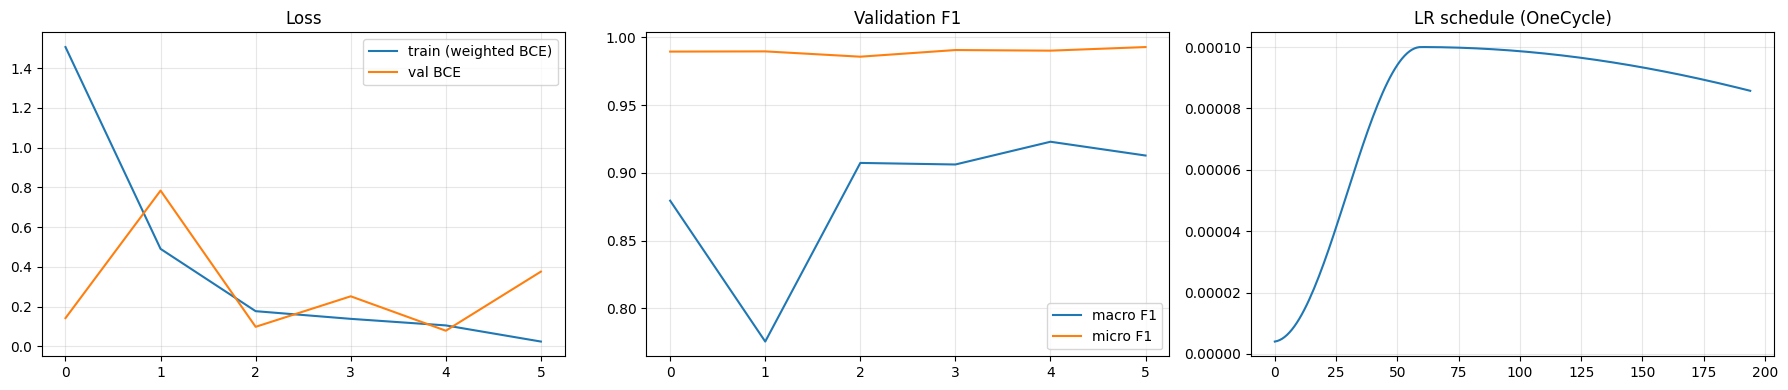

In [30]:
metrics = []
for cb in trainer.callbacks:
    if hasattr(cb, "best_model_score"):
        break

# Reconstruct from logged metrics (saved every epoch by Lightning)
logged = trainer.logged_metrics  # last epoch only — use callback_metrics history instead

api = wandb.Api()
runs = api.runs("polo-kris-78-900-kyiv-shool-of-economics/cats-and-dogs",
                filters={"display_name": f"{MODEL_NAME}_fold{FOLD}"})
run = runs[0]
hist_df = run.history()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

train_loss = hist_df["train_loss"].dropna().reset_index(drop=True)
val_bce = hist_df["val_bce"].dropna().reset_index(drop=True)
axes[0].plot(train_loss.index, train_loss.values, label="train (weighted BCE)")
axes[0].plot(val_bce.index, val_bce.values, label="val BCE")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

macro = hist_df["val_macro_f1"].dropna().reset_index(drop=True)
micro = hist_df["val_micro_f1"].dropna().reset_index(drop=True)
axes[1].plot(macro.index, macro.values, label="macro F1")
axes[1].plot(micro.index, micro.values, label="micro F1")
axes[1].set_title("Validation F1"); axes[1].legend(); axes[1].grid(alpha=0.3)

lr = hist_df["lr-AdamW"].dropna().reset_index(drop=True)
axes[2].plot(lr.index, lr.values)
axes[2].set_title("LR schedule (OneCycle)"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"/kaggle/working/{MODEL_NAME}_curves.png", dpi=120)
plt.show()

#### Experiments log

In [31]:
row = {
    "model": MODEL_NAME, "fold": FOLD, "lr": LR, "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE, "drop_rate": DROP_RATE, "drop_path": DROP_PATH,
    "epochs": EPOCHS,
    "best_val_macro_f1": float(callbacks[0].best_model_score),
}
exp_path = "/kaggle/working/experiments.csv"
exp_df = pd.DataFrame([row])
exp_df.to_csv(exp_path, mode="a", header=not os.path.exists(exp_path), index=False)

In [32]:
_, _, _, val_probs, val_targets = validate(model, val_loader, DEVICE)

grid = np.arange(0.05, 0.96, 0.01)
best_thresholds = np.array([
    grid[int(np.argmax([f1_score(val_targets[:, c], val_probs[:, c] >= t, zero_division=0)
                        for t in grid]))]
    for c in range(len(CLASSES))
])
print("Thresholds:", dict(zip(CLASSES, best_thresholds.round(2))))
print("Macro F1 @0.5:  ", f1_score(val_targets, (val_probs >= 0.5).astype(int),
                                   average="macro", zero_division=0))
print("Macro F1 tuned: ", f1_score(val_targets, (val_probs >= best_thresholds).astype(int),
                                   average="macro", zero_division=0))

Thresholds: {'Cat': np.float64(0.66), 'Dog': np.float64(0.07), 'Moris': np.float64(0.25), 'Motya': np.float64(0.05), 'Biatrix': np.float64(0.05)}
Macro F1 @0.5:   0.9884344369620613
Macro F1 tuned:  0.9889279611103239


## Submission

In [33]:
TEST_PATH = "/kaggle/input/competitions/cats-and-dogs/test"

test_df = pd.read_csv("/kaggle/input/competitions/cats-and-dogs/test.csv")
for c in CLASSES:
    test_df[c] = 0

test_dataset = CatDogDataset(test_df, CLASSES, TEST_PATH, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False,
                         num_workers=2, pin_memory=True)

In [34]:
@torch.no_grad()
def predict_probs(model, loader, device, tta=False):
    model.eval()
    out = []
    for X, _ in loader:
        X = X.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            probs = torch.sigmoid(model(X).float())
            if tta:
                probs_flip = torch.sigmoid(model(torch.flip(X, dims=[3])).float())
                probs = (probs + probs_flip) / 2
        out.append(probs.cpu())
    return enforce_hierarchy(torch.cat(out).numpy())

test_probs = predict_probs(model, test_loader, DEVICE, tta=True)
print(test_probs.shape)

(18673, 5)


In [35]:
THRESHOLDS = best_thresholds if "best_thresholds" in globals() else np.full(len(CLASSES), 0.5)
print("Thresholds:", dict(zip(CLASSES, np.round(THRESHOLDS, 2))))

preds = (test_probs >= THRESHOLDS).astype(int)
preds[:, 0] = np.maximum(preds[:, 0], np.maximum(preds[:, 2], preds[:, 3]))
preds[:, 1] = np.maximum(preds[:, 1], preds[:, 4])

print("Positive rate per class:", dict(zip(CLASSES, preds.mean(axis=0).round(3))))

Thresholds: {'Cat': np.float64(0.66), 'Dog': np.float64(0.07), 'Moris': np.float64(0.25), 'Motya': np.float64(0.05), 'Biatrix': np.float64(0.05)}
Positive rate per class: {'Cat': np.float64(0.418), 'Dog': np.float64(0.411), 'Moris': np.float64(0.009), 'Motya': np.float64(0.008), 'Biatrix': np.float64(0.01)}


In [36]:
sample = pd.read_csv("/kaggle/input/competitions/cats-and-dogs/sample_submission.csv")

sub = pd.DataFrame(preds, columns=CLASSES)
sub.insert(0, "image_id", test_df["image_id"].values)

missing = set(sample.columns) - set(sub.columns)
if missing:
    raise ValueError(f"Бракує колонок з sample_submission: {missing}")

sub = sub[sample.columns]
assert len(sub) == len(test_df)

sub.to_csv("/kaggle/working/submission.csv", index=False)
print(sub.head())

                                   image_id  Cat  Dog  Moris  Motya  Biatrix
0  12c79b0a4bd444ca7e5f730b86824b9279d3cd24    0    0      0      0        0
1  dd9440332972c9c5cecb5bf3cfb3329d6b2e422c    0    1      0      0        0
2  ac89f642faef21c92d622d882943e9065600354a    0    0      0      0        0
3  7245e7046ae54da95dbddc24ae814b3c61cc6237    1    0      0      0        0
4  d2b76179615de57b54cb00d094fba50810d96127    1    0      0      0        0


In [37]:
!pip install --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.5 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [38]:
SUB_PATH = "/kaggle/working/submission.csv"

!kaggle competitions submit -c cats-and-dogs -f {SUB_PATH} -m "test submission"

100%|████████████████████████████████████████| 930k/930k [00:00<00:00, 2.75MB/s]
3 submissions remaining today.
Successfully submitted to Cats and Dogs++

## Esembling 

In [ ]:
N_FOLDS = 3

test_probs_sum = np.zeros((len(test_df), len(CLASSES)))
oof_probs, oof_targets, fold_scores = [], [], []

for fold_i in range(N_FOLDS):
    print(f"\n{'='*60}\nFold {fold_i}\n{'='*60}")

    tr = train_df[train_df["fold"] != fold_i].reset_index(drop=True)
    vl = train_df[train_df["fold"] == fold_i].reset_index(drop=True)
    dm_f = CatDogDataModule(tr, vl, CLASSES, DATA_PATH, train_transform, val_transform)

    m = build_model(MODEL_NAME).to(DEVICE)
    reuse_path = f"/kaggle/working/{MODEL_NAME}_fold{fold_i}_best.pt"

    if fold_i == FOLD and os.path.exists(reuse_path):

        m.load_state_dict(torch.load(reuse_path, map_location=DEVICE))
        print("  reusing the 0.97458 single-model checkpoint")
    else:

        pos_f = tr[CLASSES].sum().values.astype(np.float32)
        pw_f = torch.tensor((len(tr) - pos_f) / np.clip(pos_f, 1, None),
                            dtype=torch.float32, device=DEVICE)

        lit_f = CatDogLitModel(model_name=MODEL_NAME, lr=LR, weight_decay=WEIGHT_DECAY,
                               epochs=EPOCHS, pos_weight=pw_f,
                               drop_rate=DROP_RATE, drop_path=DROP_PATH)
        ckpt_cb = ModelCheckpoint(monitor="val_macro_f1", mode="max", save_top_k=1,
                                  dirpath=f"/kaggle/working/ckpts_fold{fold_i}/")
        wandb.init(project="cats-and-dogs", name=f"{MODEL_NAME}_cv_fold{fold_i}", reinit=True)
        trainer_f = pl.Trainer(max_epochs=EPOCHS, accelerator="gpu", devices=1,
                               precision="16-mixed", gradient_clip_val=1.0,
                               logger=WandbLogger(experiment=wandb.run, log_model=False),
                               callbacks=[ckpt_cb, LearningRateMonitor(logging_interval="step")],
                               log_every_n_steps=10)
        trainer_f.fit(lit_f, dm_f)
        wandb.finish()

        sd = torch.load(ckpt_cb.best_model_path)["state_dict"]
        m.load_state_dict({k.replace("model.", "", 1): v for k, v in sd.items()
                           if k.startswith("model.")})
        torch.save(m.state_dict(), f"/kaggle/working/{MODEL_NAME}_cvfold{fold_i}.pt")
        del lit_f, trainer_f

    # OOF predictions 
    macro, _, _, vp, vt = validate(m, dm_f.val_dataloader(), DEVICE)
    oof_probs.append(vp); oof_targets.append(vt); fold_scores.append(macro)
    print(f"  Fold {fold_i} val macro F1 @0.5: {macro:.4f}")

    test_probs_sum += predict_probs(m, test_loader, DEVICE, tta=True)

    del m
    torch.cuda.empty_cache()

test_probs_ensemble = test_probs_sum / N_FOLDS
print(f"\nCV macro F1: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

# Re-tune class thresholds on OOF predictions
oof_probs = np.concatenate(oof_probs); oof_targets = np.concatenate(oof_targets)
grid = np.arange(0.05, 0.96, 0.01)
best_thresholds = np.array([
    grid[np.argmax([f1_score(oof_targets[:, c], oof_probs[:, c] >= t, zero_division=0)
                    for t in grid])]
    for c in range(len(CLASSES))])
print("OOF thresholds:", dict(zip(CLASSES, best_thresholds.round(2))))
print("OOF macro F1 tuned:", f1_score(oof_targets, (oof_probs >= best_thresholds).astype(int),
                                      average="macro", zero_division=0))


Fold 0
  reusing the 0.97458 single-model checkpoint


In [ ]:
ens_preds = (test_probs_ensemble >= best_thresholds).astype(int)
ens_preds[:, 0] = np.maximum(ens_preds[:, 0], np.maximum(ens_preds[:, 2], ens_preds[:, 3]))
ens_preds[:, 1] = np.maximum(ens_preds[:, 1], ens_preds[:, 4])

sample = pd.read_csv("/kaggle/input/competitions/cats-and-dogs/sample_submission.csv")
ens_sub = pd.DataFrame(ens_preds, columns=CLASSES)
ens_sub.insert(0, "image_id", test_df["image_id"].values)
ens_sub = ens_sub[sample.columns]
ens_sub.to_csv("/kaggle/working/submission_ensemble.csv", index=False)

print("Ensemble positive rates:")
print(dict(zip(CLASSES, ens_preds.mean(axis=0).round(3))))

SUB_PATH = "/kaggle/working/submission_ensemble.csv"
!kaggle competitions submit -c cats-and-dogs -f {SUB_PATH} -m "convnextv2 {N_FOLDS}-fold CV + TTA + OOF thresholds"